## 1. Import required libraries

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

## 2. Load the Seeds dataset

In [2]:
df = pd.read_csv("seeds_new.csv")
print("First five rows:")
print(df.head())

First five rows:
    Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
0  15.26      14.84       0.8710             5.763            3.312   
1  14.88      14.57       0.8811             5.554            3.333   
2  14.29      14.09       0.9050             5.291            3.337   
3  13.84      13.94       0.8955             5.324            3.379   
4  16.14      14.99       0.9034             5.658            3.562   

   Asymmetry coefficient  Length of kernel groove  Class (1, 2, 3) Unnamed: 8  \
0                  2.221                    5.220                1        NaN   
1                  1.018                    4.956                1        NaN   
2                  2.699                    4.825                1        NaN   
3                  2.259                    4.805                1        NaN   
4                  1.355                    5.175                1        NaN   

  Unnamed: 9  
0        NaN  
1        NaN  
2        NaN  
3        

In [3]:
print("Last five rows:")
print(df.tail())

Last five rows:
      Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
205  12.19      13.20       0.8783             5.137            2.981   
206  11.23      12.88       0.8511             5.140            2.795   
207  13.20      13.66       0.8883             5.236            3.232   
208  11.84      13.21       0.8521             5.175            2.836   
209  12.30      13.34       0.8684             5.243            2.974   

     Asymmetry coefficient  Length of kernel groove  Class (1, 2, 3)  \
205                  3.631                    4.870                3   
206                  4.325                    5.003                3   
207                  8.315                    5.056                3   
208                  3.598                    5.044                3   
209                  5.637                    5.063                3   

    Unnamed: 8 Unnamed: 9  
205        NaN        NaN  
206        NaN        NaN  
207        NaN        NaN  


In [4]:
print("Dataset shape:")
print(df.shape)

Dataset shape:
(210, 10)


In [5]:
print("Column names:")
print(df.columns)

Column names:
Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)', 'Unnamed: 8', 'Unnamed: 9'],
      dtype='object')


In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [7]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Area                         0
Perimeter                    0
Compactness                  0
Length of kernel             0
Width of kernel              0
Asymmetry coefficient        0
Length of kernel groove      0
Class (1, 2, 3)              0
Unnamed: 8                 208
Unnamed: 9                 209
dtype: int64


In [8]:
print("Number of duplicate rows:")
print(df.duplicated().sum())

Number of duplicate rows:
0


In [9]:
print("Statistical summary:")
print(df.describe())

Statistical summary:
             Area   Perimeter  Compactness  Length of kernel  Width of kernel  \
count  210.000000  210.000000   210.000000        210.000000       210.000000   
mean    14.847524   14.559286     0.870999          5.628533         3.258605   
std      2.909699    1.305959     0.023629          0.443063         0.377714   
min     10.590000   12.410000     0.808100          4.899000         2.630000   
25%     12.270000   13.450000     0.856900          5.262250         2.944000   
50%     14.355000   14.320000     0.873450          5.523500         3.237000   
75%     17.305000   15.715000     0.887775          5.979750         3.561750   
max     21.180000   17.250000     0.918300          6.675000         4.033000   

       Asymmetry coefficient  Length of kernel groove  Class (1, 2, 3)  
count             210.000000               210.000000       210.000000  
mean                3.700201                 5.408071         2.000000  
std                 1.503557  

## 3. Clean the dataset

In [10]:
df = pd.read_csv("seeds_new.csv")

df = df.loc[:, ~df.columns.str.startswith("Unnamed")]  
df = df.drop_duplicates()
df = df.dropna()

target_column = "Class (1, 2, 3)"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' not found. "
        f"Available columns: {list(df.columns)}"
    )

print("Cleaned shape:", df.shape)

Cleaned shape: (210, 8)


## 4. Separate input features and target

In [11]:
X = df.drop(target_column, axis=1)
y_original = df[target_column].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y_original.shape)
print("Original classes:")
print(sorted(y_original.unique()))

y = y_original - 1
print("Encoded classes:")
print(sorted(y.unique()))

Feature shape: (210, 7)
Target shape: (210,)
Original classes:
[np.int64(1), np.int64(2), np.int64(3)]
Encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


## 5. Split data into training and testing sets

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 168
Testing samples: 42


## 6. Standardize the input features

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Build the Artificial Neural Network

In [14]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

## 8. Compile the model

In [15]:
model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ANN Model Summary:")
model.summary()

ANN Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Early stopping

In [16]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

## 10. Train the model

In [17]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.3209 - loss: 1.0422 - val_accuracy: 0.8235 - val_loss: 0.6782
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.7537 - loss: 0.6261 - val_accuracy: 0.8529 - val_loss: 0.4052
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8955 - loss: 0.3819 - val_accuracy: 0.8824 - val_loss: 0.3005
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9104 - loss: 0.2568 - val_accuracy: 0.9118 - val_loss: 0.2554
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9104 - loss: 0.2102 - val_accuracy: 0.9412 - val_loss: 0.2155
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9254 - loss: 0.1842 - val_accuracy: 0.9412 - val_loss: 0.1868
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9328 - loss: 0.1604 - val_accuracy: 0.9412 - val_loss: 0.1723
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9328 - loss: 0.1424 - val_accuracy: 0.9412 - val_loss:

## 11. Plot training and validation accuracy

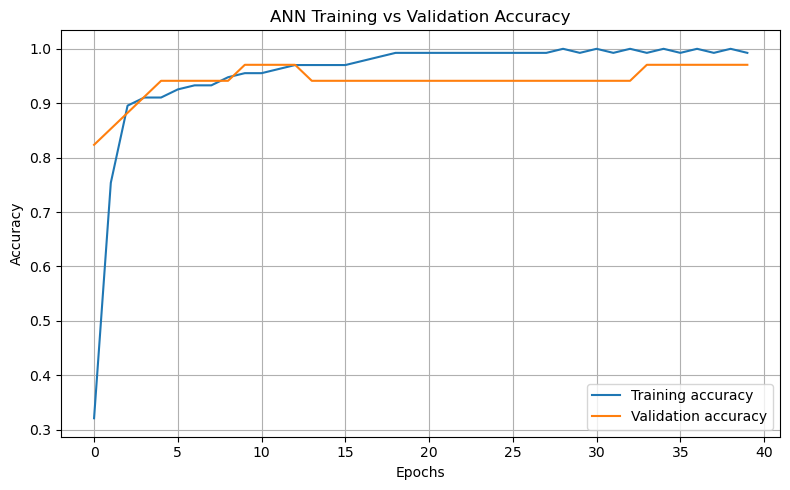

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

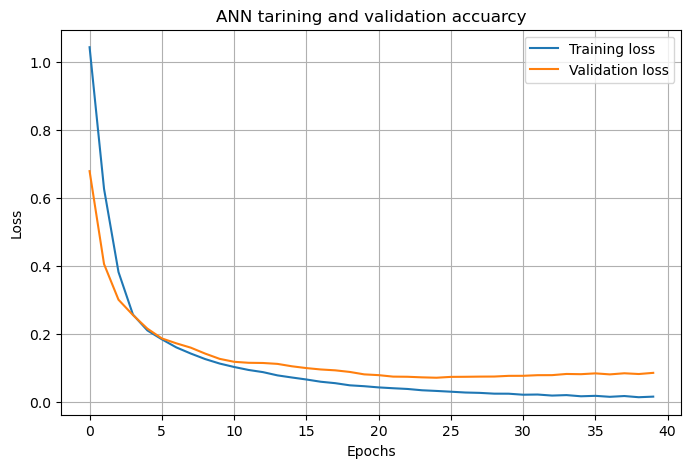

In [30]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.title("ANN tarining and validation accuarcy")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## 12. Evaluate the model on test data

In [19]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.42995548248291016
Test accuracy: 0.8571428656578064


## 13. Predict class probabilities

In [20]:
y_prob = model.predict(X_test_scaled, verbose=0)

print("First five prediction probabilities:")
print(y_prob[:5])

First five prediction probabilities:
[[9.9938774e-01 2.9204311e-04 3.2023163e-04]
 [8.1757912e-03 6.3200998e-05 9.9176097e-01]
 [5.0844175e-01 4.8865947e-01 2.8987867e-03]
 [2.3688308e-05 2.0929442e-06 9.9997413e-01]
 [5.0972878e-05 9.9994898e-01 3.9291230e-08]]


## 14. Convert probabilities to predicted class labels

In [21]:
y_pred = np.argmax(y_prob, axis=1)

print("First ten encoded predictions:")
print(y_pred[:10])

y_pred_original = y_pred + 1
y_test_original = y_test.to_numpy() + 1

print("First ten predictions in original classes:")
print(y_pred_original[:10])

First ten encoded predictions:
[0 2 0 2 1 2 1 0 1 1]
First ten predictions in original classes:
[1 3 1 3 2 3 2 1 2 2]


## 15. Compare actual and predicted classes

In [22]:
comparison = pd.DataFrame({
    "Actual class": y_test_original,
    "Predicted class": y_pred_original
})

print("Actual vs Predicted:")
print(comparison.head(10))

Actual vs Predicted:
   Actual class  Predicted class
0             1                1
1             3                3
2             2                1
3             3                3
4             2                2
5             3                3
6             2                2
7             1                1
8             2                2
9             2                2


## 16. Calculate evaluation metrics

In [23]:
accuracy = accuracy_score(y_test_original, y_pred_original)
precision = precision_score(y_test_original, y_pred_original,
                            average="weighted", zero_division=0)
recall = recall_score(y_test_original, y_pred_original,
                      average="weighted", zero_division=0)
f1 = f1_score(y_test_original, y_pred_original,
              average="weighted", zero_division=0)

print("Evaluation Metrics")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 score:", f1)

Evaluation Metrics
Accuracy: 0.8571428571428571
Precision: 0.8633986928104576
Recall: 0.8571428571428571
F1 score: 0.849925843529848


In [24]:
metrics = pd.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1 score": [f1]
})

print("Metrics table:")
print(metrics.round(4))

Metrics table:
   Accuracy  Precision  Recall  F1 score
0    0.8571     0.8634  0.8571    0.8499


## 17. Classification report

In [25]:
print("Classification Report:")
print(classification_report(y_test_original, y_pred_original,
                            labels=[1, 2, 3], zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           1       0.90      0.64      0.75        14
           2       0.87      0.93      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



## 18. Generate and display confusion matrix

In [26]:
cm = confusion_matrix(y_test_original, y_pred_original, labels=[1, 2, 3])

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 9  2  3]
 [ 1 13  0]
 [ 0  0 14]]


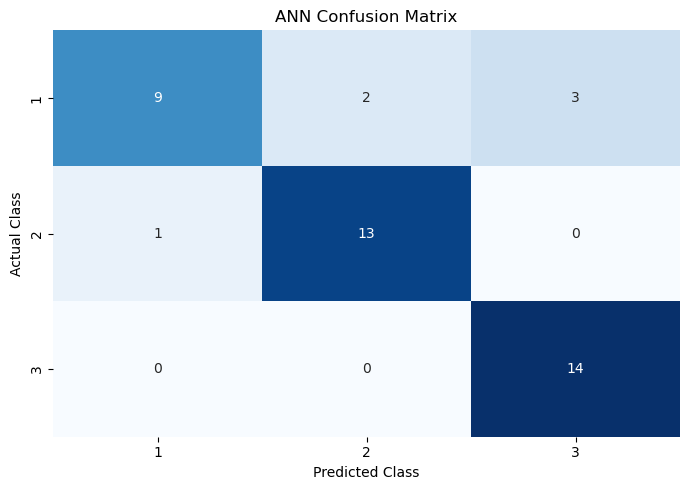

In [27]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

## 19. Save the trained model

In [28]:
model.save("lab6_ann_model.keras")
print("Model saved successfully as lab6_ann_model.keras")

Model saved successfully as lab6_ann_model.keras


## 20. Save evaluation metrics

In [29]:
metrics.to_csv("lab6_evaluation_metrics.csv", index=False)
print("Evaluation metrics saved successfully.")
print("\nLab 6 execution completed successfully.")

Evaluation metrics saved successfully.

Lab 6 execution completed successfully.
